<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/topics_in_qm/aqm_ch05_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Topics in Quantum Mechanics* — `aqm_ch05_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# AQM Chapter 5 — Discrete Symmetries: Figures
Run in Colab. Last cell auto-downloads `ch05_figures.zip`.

| Fig | Content |
|-----|--------|
| 01 | Parity of hydrogen wavefunctions: $s$ (even), $p$ (odd), $d$ (even) |
| 02 | Laporte's rule: allowed/forbidden E1 transitions |
| 03 | Kramers degeneracy: doublet at $B=0$, Zeeman splitting |
| 04 | Time reversal $\mathcal{T}^2=-1$ (spin-½) vs $\mathcal{T}^2=+1$ (spin-0) |
| 05 | Wu experiment: parity violation in $\beta$-decay |
| 06 | Electric dipole moment: $\mathcal{PT}$-violation, EDM limits |


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrow, Arc, FancyArrowPatch
from matplotlib.path import Path
import matplotlib.patheffects as pe
import os

plt.rcParams.update({
    'figure.facecolor':'#1e1e2e','axes.facecolor':'#1e1e2e',
    'text.color':'#cdd6f4','axes.labelcolor':'#cdd6f4',
    'xtick.color':'#cdd6f4','ytick.color':'#cdd6f4',
    'axes.edgecolor':'#45475a','grid.color':'#313244',
    'font.family':'DejaVu Sans','font.size':12,
    'axes.titlesize':13,'axes.titleweight':'bold',
    'mathtext.fontset':'cm',
})
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; BG='#1e1e2e'
os.makedirs('figures/ch05', exist_ok=True)
SAVE = lambda n: plt.savefig(f'figures/ch05/{n}', dpi=150,
                              bbox_inches='tight', facecolor=BG)
print('Setup complete.')


Setup complete.


## Fig 01 — Parity of Hydrogen Wavefunctions

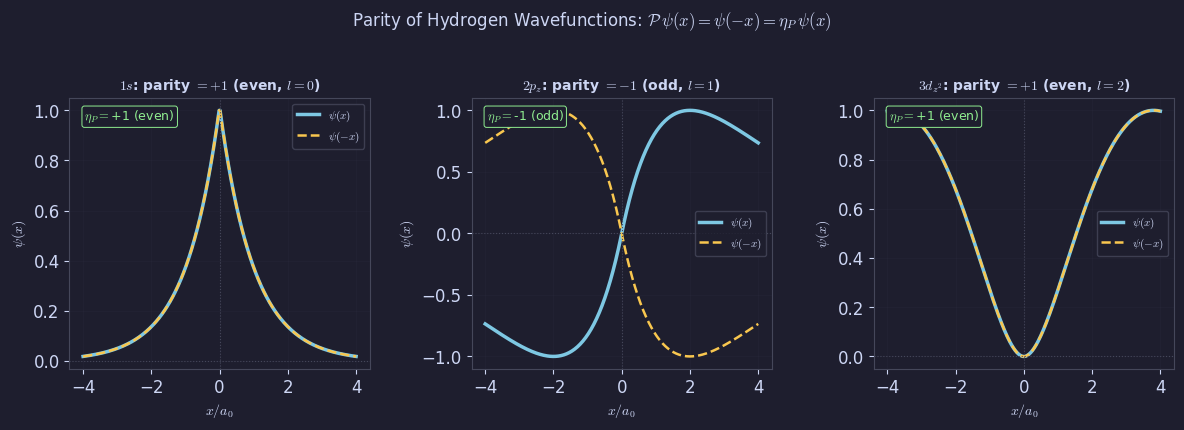

Fig 01 saved.


In [2]:

# Fig 01: Hydrogen wavefunctions — parity under x -> -x
# s (even), p (odd), d (even)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
titles = [r'$1s$: parity $= +1$ (even, $l=0$)',
          r'$2p_z$: parity $= -1$ (odd, $l=1$)',
          r'$3d_{z^2}$: parity $= +1$ (even, $l=2$)']
x = np.linspace(-4, 4, 300)

for ax, (l, m, n_eff), title in zip(axes,
        [(0,0,1),(1,0,2),(2,0,3)], titles):
    r = np.abs(x)
    # Radial: simplified Laguerre-like function
    rho = 2*r/n_eff
    if l==0:
        R = np.exp(-rho/2)
    elif l==1:
        R = rho * np.exp(-rho/2)
    else:
        R = rho**2 * (1 - rho/6) * np.exp(-rho/2)
        R = np.abs(R)   # keep positive for display
    # Angular: Y_l^0 on z-axis -> simplified as sign factor
    psi = R * (1.0 if l%2==0 else np.sign(x))
    psi /= np.max(np.abs(psi) + 1e-12)

    ax.plot(x, psi, color=BLUE,   lw=2.5, label=r'$\psi(x)$')
    ax.plot(x, np.where(x>=0, psi[x>=0].mean()*0+0, psi)[::-1] if False
            else np.interp(-x, x, psi),
            color=YELLOW, lw=1.8, ls='--', label=r'$\psi(-x)$')
    ax.axhline(0, color='#45475a', lw=0.8, ls=':')
    ax.axvline(0, color='#45475a', lw=0.8, ls=':')
    ax.set_title(title, color='#cdd6f4', fontsize=10)
    ax.set_xlabel(r'$x/a_0$', fontsize=10)
    ax.set_ylabel(r'$\psi(x)$', fontsize=10)
    ax.legend(fontsize=8, facecolor=BG, edgecolor='#45475a',
              labelcolor='#cdd6f4')
    ax.grid(True, alpha=0.2)
    # Label parity
    parity_lbl = '+1 (even)' if l%2==0 else '-1 (odd)'
    ax.text(0.05, 0.92, r'$\eta_P = $' + parity_lbl,
            transform=ax.transAxes, color=GREEN, fontsize=9,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=GREEN, lw=0.7))

plt.suptitle(r'Parity of Hydrogen Wavefunctions: $\mathcal{P}\,\psi(x)=\psi(-x)=\eta_P\,\psi(x)$',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig01_parity_wavefunctions.png'); plt.show(); print('Fig 01 saved.')


## Fig 02 — Parity Selection Rules (Laporte)

<>:59: SyntaxWarning: invalid escape sequence '\D'
<>:60: SyntaxWarning: invalid escape sequence '\D'
<>:59: SyntaxWarning: invalid escape sequence '\D'
<>:60: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_41/3337170561.py:59: SyntaxWarning: invalid escape sequence '\D'
  ax.plot([],[],'-',color=BLUE,lw=2, label='Allowed (E1, $\Delta l=\pm1$)')
/tmp/ipykernel_41/3337170561.py:60: SyntaxWarning: invalid escape sequence '\D'
  ax.plot([],[],'x',color=RED, ms=8, mew=2, label='Forbidden ($\Delta l\neq\pm1$)')


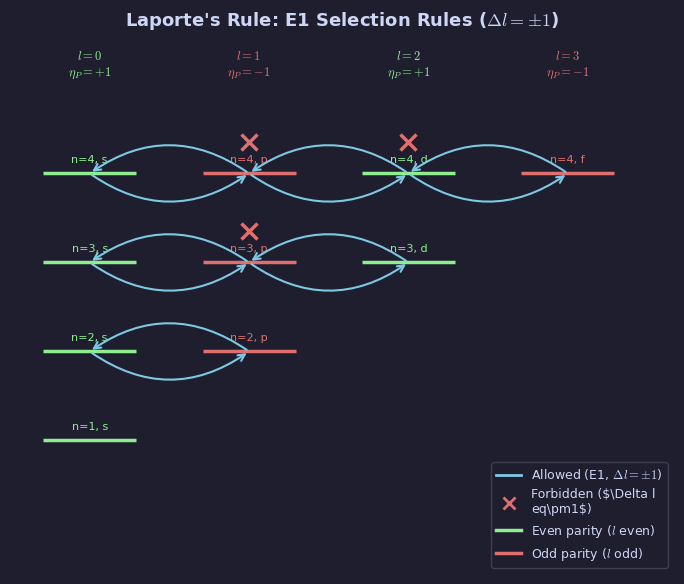

Fig 02 saved.


In [3]:

# Fig 02: Parity selection rules for electric dipole transitions
# Allowed: l -> l+/-1 (parity changes); Forbidden: l -> l, l+/-2

fig, ax = plt.subplots(figsize=(7, 6))
ax.set_xlim(0, 5); ax.set_ylim(-0.5, 5.5)
ax.axis('off')

# Energy levels (n=1..4, labelled by l)
levels = {
    (1,0): (1.0, 'n=1, s', GREEN),
    (2,0): (2.0, 'n=2, s', GREEN),
    (2,1): (2.0, 'n=2, p', RED),
    (3,0): (3.0, 'n=3, s', GREEN),
    (3,1): (3.0, 'n=3, p', RED),
    (3,2): (3.0, 'n=3, d', GREEN),
    (4,0): (4.0, 'n=4, s', GREEN),
    (4,1): (4.0, 'n=4, p', RED),
    (4,2): (4.0, 'n=4, d', GREEN),
    (4,3): (4.0, 'n=4, f', RED),
}
# x positions by l
l_x = {0: 0.6, 1: 1.8, 2: 3.0, 3: 4.2}

# Draw levels
for (n,l),(E,lbl,col) in levels.items():
    xp = l_x[l]
    ax.hlines(E, xp-0.35, xp+0.35, colors=col, lw=2.5)
    ax.text(xp, E+0.12, lbl, ha='center', color=col, fontsize=8)

# Parity labels at top
for l, xp in l_x.items():
    eta = '+1 (even)' if l%2==0 else '-1 (odd)'
    col = GREEN if l%2==0 else RED
    ax.text(xp, 5.1, f'$l={l}$\n$\\eta_P={"+1" if l%2==0 else "-1"}$',
            ha='center', color=col, fontsize=9)

# Allowed transitions (Δl=±1): arrows
allowed = [(2,0,1),(2,1,0),(3,0,1),(3,1,0),(3,1,2),(3,2,1),
           (4,0,1),(4,1,0),(4,1,2),(4,2,1),(4,2,3),(4,3,2)]
for n,l1,l2 in allowed:
    if l2 > 4: continue
    x1,x2 = l_x[l1], l_x[l2]
    E_lev  = n*1.0
    ax.annotate('', xy=(x2, E_lev), xytext=(x1, E_lev),
                arrowprops=dict(arrowstyle='->', color=BLUE,
                                lw=1.5, mutation_scale=12,
                                connectionstyle='arc3,rad=0.35'))

# Forbidden transitions (Δl=0,±2): red crosses
forbidden = [(3,0,2),(4,0,2),(4,1,3)]
for n,l1,l2 in forbidden:
    if l2>3: continue
    x1,x2 = l_x[l1], l_x[l2]
    E_lev  = n*1.0
    xm = (x1+x2)/2; ym = E_lev+0.35
    ax.plot(xm, ym, 'x', color=RED, ms=12, mew=2.5, zorder=5)

# Legend
ax.plot([],[],'-',color=BLUE,lw=2, label='Allowed (E1, $\Delta l=\pm1$)')
ax.plot([],[],'x',color=RED, ms=8, mew=2, label='Forbidden ($\Delta l\neq\pm1$)')
ax.plot([],[],'-',color=GREEN,lw=2.5,label='Even parity ($l$ even)')
ax.plot([],[],'-',color=RED,  lw=2.5,label='Odd parity ($l$ odd)')
ax.legend(fontsize=9, loc='lower right', facecolor=BG,
          edgecolor='#45475a', labelcolor='#cdd6f4')
ax.set_title("Laporte's Rule: E1 Selection Rules ($\\Delta l = \\pm 1$)",
             color='#cdd6f4', pad=10)

plt.tight_layout()
SAVE('fig02_parity_selection_rules.png'); plt.show(); print('Fig 02 saved.')


## Fig 03 — Kramers Degeneracy

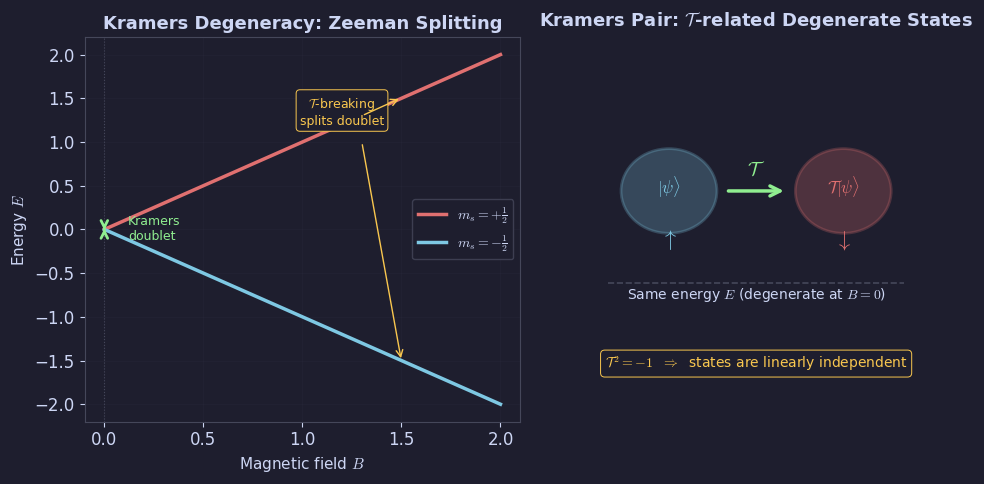

Fig 03 saved.


In [4]:

# Fig 03: Kramers degeneracy
# Left: energy levels — degenerate at B=0, split by B
# Right: conceptual diagram of T-related pair and T-breaking

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Left: Energy splitting vs B
B = np.linspace(0, 2.0, 300)
g_factor = 2.0
mu_B = 1.0
E_plus  =  0.5 * g_factor * mu_B * B
E_minus = -0.5 * g_factor * mu_B * B

ax = axes[0]
ax.plot(B, E_plus,  color=RED,  lw=2.5, label=r'$m_s = +\frac{1}{2}$')
ax.plot(B, E_minus, color=BLUE, lw=2.5, label=r'$m_s = -\frac{1}{2}$')

# Kramers pair label at B=0
ax.annotate('', xy=(0, E_plus[0]+0.01), xytext=(0, E_minus[0]-0.01),
            arrowprops=dict(arrowstyle='<->', color=GREEN, lw=2.0))
ax.text(0.12, 0, 'Kramers\ndoublet', color=GREEN, fontsize=9, va='center')
ax.axvline(0, color='#45475a', lw=0.8, ls=':')

# T-breaking annotation
ax.text(1.2, 1.2, r'$\mathcal{T}$-breaking' '\n' r'splits doublet',
        color=YELLOW, fontsize=9, ha='center',
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELLOW, lw=0.7))
ax.annotate('', xy=(1.5, E_plus[225]), xytext=(1.3, 1.3),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.0))
ax.annotate('', xy=(1.5, E_minus[225]), xytext=(1.3, 1.0),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.0))

ax.set_xlabel(r'Magnetic field $B$', fontsize=11)
ax.set_ylabel(r'Energy $E$', fontsize=11)
ax.set_title('Kramers Degeneracy: Zeeman Splitting', color='#cdd6f4')
ax.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

# Right: Schematic of T action on Kramers pair
ax2 = axes[1]
ax2.set_xlim(0, 5); ax2.set_ylim(0, 5)
ax2.axis('off')

# Draw two states as circles
for (x,y,lbl,col,spin) in [(1.5,3,'$|\\psi\\rangle$',BLUE,r'$\uparrow$'),
                              (3.5,3,'$\\mathcal{T}|\\psi\\rangle$',RED,r'$\downarrow$')]:
    circ = plt.Circle((x,y), 0.55, fc=col, alpha=0.25, ec=col, lw=2, zorder=3)
    ax2.add_patch(circ)
    ax2.text(x, y+0.05, lbl, ha='center', va='center',
             color=col, fontsize=12, fontweight='bold')
    ax2.text(x, y-0.72, spin, ha='center', color=col, fontsize=16)

# Arrow for T action
ax2.annotate('', xy=(2.85,3), xytext=(2.15,3),
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5,
                             mutation_scale=18))
ax2.text(2.5, 3.2, r'$\mathcal{T}$', color=GREEN, fontsize=14, ha='center')

# Same energy label
ax2.hlines(1.8, 0.8, 4.2, colors='#45475a', lw=1.2, ls='--')
ax2.text(2.5, 1.6, r'Same energy $E$ (degenerate at $B=0$)',
         color='#cdd6f4', ha='center', fontsize=10)

# T^2 = -1 annotation
ax2.text(2.5, 0.7,
         r'$\mathcal{T}^2 = -1$  $\Rightarrow$  states are linearly independent',
         ha='center', color=YELLOW, fontsize=10,
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELLOW, lw=0.7))

ax2.set_title("Kramers Pair: $\\mathcal{T}$-related Degenerate States",
              color='#cdd6f4', pad=8)

plt.tight_layout()
SAVE('fig03_kramers_degeneracy.png'); plt.show(); print('Fig 03 saved.')


## Fig 04 — Time Reversal: $\mathcal{T}^2$

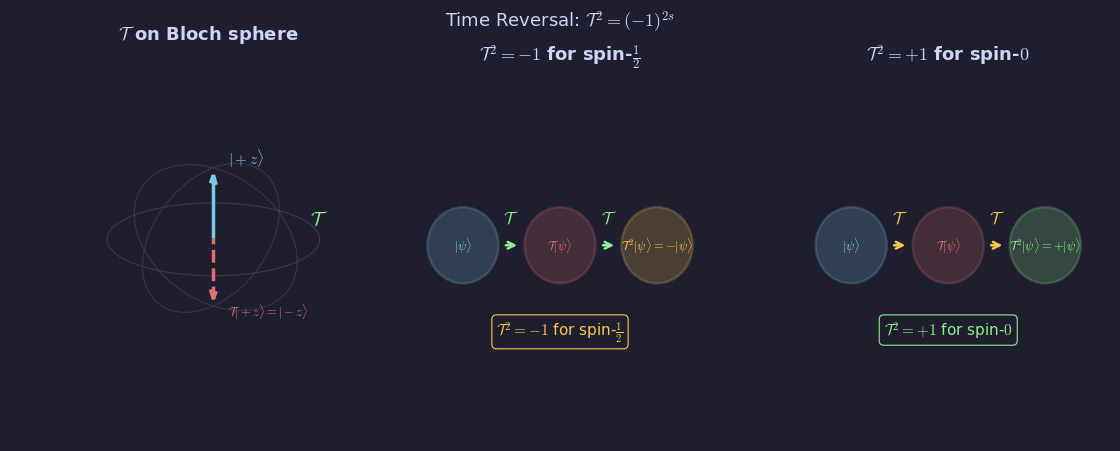

Fig 04 saved.


In [5]:

# Fig 04: Time reversal for spin-1/2
# Shows T: |+z> -> |−z> and T: |−z> -> -|+z>  (i.e. T = -i*sigma_y * K)
# Visual: Bloch sphere showing T maps north pole to south pole

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(11, 4.5))

# Left: Bloch sphere showing T action
ax1 = fig.add_subplot(1,3,1, projection='3d')
ax1.set_facecolor(BG)

phi_line = np.linspace(0,2*np.pi,200)
# Equator + two meridians
ax1.plot(np.cos(phi_line),np.sin(phi_line),np.zeros_like(phi_line),
         color='#45475a',lw=0.8,alpha=0.7)
for az in [0, np.pi/2]:
    ax1.plot(np.sin(phi_line)*np.cos(az),
             np.sin(phi_line)*np.sin(az),
             np.cos(phi_line), color='#45475a',lw=0.8,alpha=0.6)

# State |+z> and its T image |-z>
ax1.quiver(0,0,0, 0,0,0.9, color=BLUE, lw=2.5, arrow_length_ratio=0.15)
ax1.quiver(0,0,0, 0,0,-0.9, color=RED, lw=2.5, arrow_length_ratio=0.15,
           linestyle='dashed')

ax1.text(0.1,0.1,1.05, r'$|+z\rangle$', color=BLUE, fontsize=11)
ax1.text(0.1,0.1,-1.15, r'$\mathcal{T}|+z\rangle = |-z\rangle$',
         color=RED, fontsize=9)

# T arrow
ax1.text(0.65,0.65,0.15, r'$\mathcal{T}$', color=GREEN, fontsize=14)

ax1.set_xlim(-1.2,1.2); ax1.set_ylim(-1.2,1.2); ax1.set_zlim(-1.3,1.3)
ax1.set_axis_off()
ax1.set_title(r'$\mathcal{T}$ on Bloch sphere', color='#cdd6f4', pad=2)
ax1.view_init(elev=20, azim=-50)
fig.subplots_adjust(left=0.0, right=1.0)
ax1.set_position([0.0, 0.0, 0.36, 1.0])

# Middle: T^2 = -1 for spin-1/2 (schematic)
ax2 = fig.add_subplot(1,3,2)
ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_xlim(0,5); ax2.set_ylim(0,5)

states = [r'$|\psi\rangle$', r'$\mathcal{T}|\psi\rangle$', r'$\mathcal{T}^2|\psi\rangle=-|\psi\rangle$']
x_pos  = [1.0, 2.5, 4.0]
cols   = [BLUE, RED, YELLOW]

for x,lbl,col in zip(x_pos, states, cols):
    circ = plt.Circle((x,2.5),0.55,fc=col,alpha=0.20,ec=col,lw=1.8,zorder=3)
    ax2.add_patch(circ)
    ax2.text(x,2.5,lbl,ha='center',va='center',color=col,fontsize=9,fontweight='bold')

for i in range(2):
    ax2.annotate('', xy=(x_pos[i+1]-0.62,2.5), xytext=(x_pos[i]+0.62,2.5),
                 arrowprops=dict(arrowstyle='->',color=GREEN,lw=1.8,mutation_scale=12))
    ax2.text((x_pos[i]+x_pos[i+1])/2, 2.82, r'$\mathcal{T}$',
             color=GREEN, ha='center', fontsize=12)

ax2.text(2.5, 1.2, r'$\mathcal{T}^2 = -\mathbf{1}$ for spin-$\frac{1}{2}$',
         ha='center', color=YELLOW, fontsize=11,
         bbox=dict(boxstyle='round,pad=0.3',fc=BG,ec=YELLOW,lw=0.8))
ax2.set_title(r'$\mathcal{T}^2=-1$ for spin-$\frac{1}{2}$', color='#cdd6f4', pad=8)

# Right: T^2 = +1 for spin-0
ax3 = fig.add_subplot(1,3,3)
ax3.set_facecolor(BG); ax3.axis('off')
ax3.set_xlim(0,5); ax3.set_ylim(0,5)

for x,lbl,col in zip([1.0,2.5,4.0],
        [r'$|\psi\rangle$',r'$\mathcal{T}|\psi\rangle$',r'$\mathcal{T}^2|\psi\rangle=+|\psi\rangle$'],
        [BLUE,RED,GREEN]):
    circ = plt.Circle((x,2.5),0.55,fc=col,alpha=0.20,ec=col,lw=1.8,zorder=3)
    ax3.add_patch(circ)
    ax3.text(x,2.5,lbl,ha='center',va='center',color=col,fontsize=9,fontweight='bold')

for i in range(2):
    ax3.annotate('', xy=([1.0,2.5,4.0][i+1]-0.62,2.5),
                 xytext=([1.0,2.5,4.0][i]+0.62,2.5),
                 arrowprops=dict(arrowstyle='->',color=YELLOW,lw=1.8,mutation_scale=12))
    ax3.text(([1.0,2.5,4.0][i]+[1.0,2.5,4.0][i+1])/2, 2.82, r'$\mathcal{T}$',
             color=YELLOW, ha='center', fontsize=12)

ax3.text(2.5,1.2, r'$\mathcal{T}^2 = +\mathbf{1}$ for spin-$0$',
         ha='center', color=GREEN, fontsize=11,
         bbox=dict(boxstyle='round,pad=0.3',fc=BG,ec=GREEN,lw=0.8))
ax3.set_title(r'$\mathcal{T}^2=+1$ for spin-$0$', color='#cdd6f4', pad=8)

plt.suptitle(r'Time Reversal: $\mathcal{T}^2 = (-1)^{2s}$',
             color='#cdd6f4', fontsize=13, y=1.02)
SAVE('fig04_time_reversal.png'); plt.show(); print('Fig 04 saved.')


## Fig 05 — Wu Experiment: Parity Violation

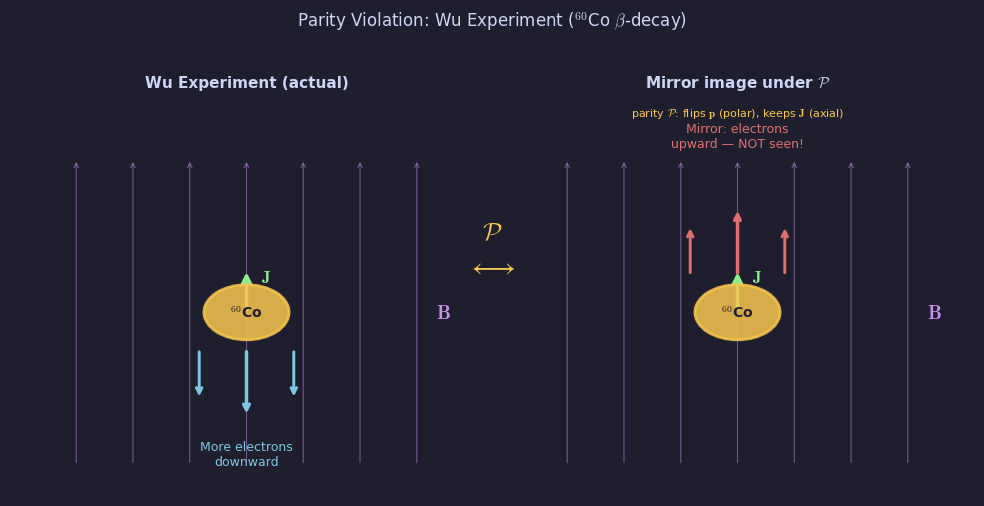

Fig 05 saved.


In [6]:

# Fig 05: Wu experiment — parity violation in beta decay
# Shows Co-60 aligned with B, electron emission asymmetric

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

def draw_experiment(ax, is_mirror, title):
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-3.0, 3.5)
    ax.axis('off')

    # B-field lines (vertical)
    for xb in [-1.8, -1.2, -0.6, 0, 0.6, 1.2, 1.8]:
        ax.annotate('', xy=(xb, 2.5), xytext=(xb, -2.5),
                    arrowprops=dict(arrowstyle='->', color=PURPLE,
                                    lw=0.8, mutation_scale=8, alpha=0.5))
    ax.text(2.0, 0, r'$\mathbf{B}$', color=PURPLE, fontsize=14, va='center')

    # Co-60 nucleus (spinning)
    nucleus = plt.Circle((0,0), 0.45, fc=YELLOW, alpha=0.85, ec=YELLOW, lw=2, zorder=5)
    ax.add_patch(nucleus)
    ax.text(0,0, r'$^{60}$Co', ha='center', va='center',
            color='#1e1e2e', fontsize=10, fontweight='bold', zorder=6)

    # Spin arrow (nuclear spin along B)
    spin_dir = +1 if not is_mirror else +1   # spin always up (axial)
    ax.annotate('', xy=(0, 0.7*spin_dir), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5,
                                mutation_scale=15))
    ax.text(0.15, 0.5*spin_dir, r'$\mathbf{J}$', color=GREEN, fontsize=12)

    # Electron emission
    if not is_mirror:
        # Actual: electrons emitted downward (opposite to B and J)
        e_dir = -1; e_label = r'$e^-$ (observed)'; e_col = BLUE
        ax.text(0, -2.5, 'More electrons\ndownward', ha='center',
                color=BLUE, fontsize=9)
    else:
        # Mirror: parity flips p (polar) but not J (axial) -> electrons upward
        e_dir = +1; e_label = r'$e^-$ (mirror)'; e_col = RED
        ax.text(0, 2.7, 'Mirror: electrons\nupward — NOT seen!',
                ha='center', color=RED, fontsize=9)

    for xoff in [-0.5, 0, 0.5]:
        scale = 1.0 if xoff==0 else 0.6
        ax.annotate('', xy=(xoff, 0.7*e_dir*scale + e_dir*1.0),
                    xytext=(xoff, e_dir*0.6),
                    arrowprops=dict(arrowstyle='->', color=e_col,
                                    lw=1.5+scale, mutation_scale=10))

    ax.set_title(title, color='#cdd6f4', fontsize=11, pad=8)
    ax.text(0, 3.2, 'parity $\\mathcal{P}$: flips $\\mathbf{p}$ (polar), keeps $\\mathbf{J}$ (axial)' if is_mirror else '',
            ha='center', color=YELLOW, fontsize=8)

draw_experiment(axes[0], False, 'Wu Experiment (actual)')
draw_experiment(axes[1], True,  r'Mirror image under $\mathcal{P}$')

# Parity arrow between panels
fig.text(0.50, 0.55, r'$\mathcal{P}$', ha='center', fontsize=18,
         color=YELLOW, fontweight='bold')
fig.text(0.50, 0.48, r'$\longleftrightarrow$', ha='center', fontsize=20, color=YELLOW)

plt.suptitle(r'Parity Violation: Wu Experiment ($^{60}$Co $\beta$-decay)',
             color='#cdd6f4', fontsize=12, y=1.01)
plt.tight_layout()
SAVE('fig05_wu_experiment.png'); plt.show(); print('Fig 05 saved.')


## Fig 06 — Electric Dipole Moment

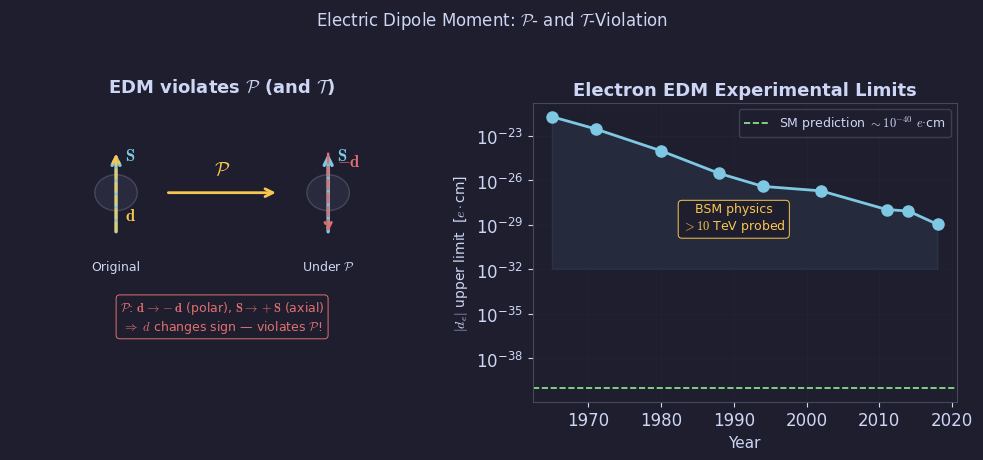

Fig 06 saved.


In [7]:

# Fig 06: Electric dipole moment — PT violation
# Shows d || S, and how P and T both flip sign -> d must be 0 if PT conserved
# Also historical timeline of electron EDM limits

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Left: Schematic of EDM violation of P and T
ax = axes[0]
ax.set_xlim(0, 6); ax.set_ylim(0, 5)
ax.axis('off')

configs = [
    (1.5, 3.5, r'$\mathbf{S}$', r'$\mathbf{d}$', BLUE,  YELLOW, 'Original'),
    (4.5, 3.5, r'$\mathbf{S}$', r'$-\mathbf{d}$', BLUE, RED,    r'Under $\mathcal{P}$'),
]
for x,y,sl,dl,sc,dc,lbl in configs:
    # Spin arrow (up)
    ax.annotate('', xy=(x,y+0.7), xytext=(x,y-0.7),
                arrowprops=dict(arrowstyle='->',color=sc,lw=2.5,mutation_scale=14))
    ax.text(x+0.12, y+0.55, sl, color=sc, fontsize=12)
    # Dipole arrow (up or down)
    sign = -1 if '-' in dl else +1
    ax.annotate('', xy=(x,y+0.7*sign), xytext=(x,y-0.7*sign),
                arrowprops=dict(arrowstyle='->',color=dc,lw=1.8,
                                linestyle='dashed',mutation_scale=12))
    ax.text(x+0.12, y-0.45*sign, dl, color=dc, fontsize=12)
    ax.text(x, y-1.3, lbl, ha='center', color='#cdd6f4', fontsize=9)
    circ = plt.Circle((x,y),0.3,fc='#2a2a3e',ec='#45475a',lw=1,zorder=2)
    ax.add_patch(circ)

ax.annotate('', xy=(3.8,3.5), xytext=(2.2,3.5),
            arrowprops=dict(arrowstyle='->',color=YELLOW,lw=2.,mutation_scale=14))
ax.text(3.0, 3.8, r'$\mathcal{P}$', color=YELLOW, ha='center', fontsize=14)

ax.text(3.0, 1.2,
        r'$\mathcal{P}$: $\mathbf{d}\to-\mathbf{d}$ (polar), $\mathbf{S}\to+\mathbf{S}$ (axial)' '\n'
        r'$\Rightarrow$ $d$ changes sign — violates $\mathcal{P}$!',
        ha='center', color=RED, fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=RED, lw=0.7))
ax.set_title(r'EDM violates $\mathcal{P}$ (and $\mathcal{T}$)', color='#cdd6f4', pad=8)

# Right: historical EDM limits (log scale)
ax2 = axes[1]
years = np.array([1965, 1971, 1980, 1988, 1994, 2002, 2011, 2014, 2018])
limits = np.array([2e-22, 3e-23, 1e-24, 3e-26, 4e-27, 2e-27, 1.1e-28, 8.7e-29, 1.1e-29])

ax2.semilogy(years, limits, 'o-', color=BLUE, lw=2., ms=8, zorder=5)
ax2.fill_between(years, limits, limits[-1]*1e-3,
                 color=BLUE, alpha=0.08)

# SM prediction (roughly 10^-40 e.cm)
ax2.axhline(1e-40, color=GREEN, lw=1.2, ls='--',
            label=r'SM prediction $\sim 10^{-40}$ $e$·cm')

# BSM sensitivity annotation
ax2.text(1990, 5e-30,
         'BSM physics\n$> 10$ TeV probed',
         color=YELLOW, fontsize=9, ha='center',
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELLOW, lw=0.7))

ax2.set_xlabel('Year', fontsize=11)
ax2.set_ylabel(r'$|d_e|$ upper limit  [$e\cdot$cm]', fontsize=10)
ax2.set_title('Electron EDM Experimental Limits', color='#cdd6f4')
ax2.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2, which='both')

plt.suptitle(r'Electric Dipole Moment: $\mathcal{P}$- and $\mathcal{T}$-Violation',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig06_edm.png'); plt.show(); print('Fig 06 saved.')


---
## ZIP & Download

In [8]:

import shutil, os
z = shutil.make_archive('ch05_figures','zip','figures/ch05')
print(f'ZIP: {z}, {os.path.getsize(z)//1024} KB')
try:
    from google.colab import files
    files.download('ch05_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — ch05_figures.zip in working directory.')


ZIP: /home/claude/ch05_figures.zip, 481 KB
Not in Colab — ch05_figures.zip in working directory.
